In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00320/student.zip"

import zipfile
import io
import requests

response = requests.get(url)
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    df = pd.read_csv(z.open("student-mat.csv"), sep=";")

df.head()


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:

# Check the size of our dataset

print("Dataset shape:", df.shape)

# Check all column names
print("\nColumns:")
print(df.columns.tolist())

# Understand the data types
print("\nDataset information:")
df.info()


Dataset shape: (395, 33)

Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null 

In [4]:

# Check missing values

print("Missing values:")
print(df.isnull().sum().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Statistical summary
df.describe()


Missing values:
0

Duplicate rows: 0


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64


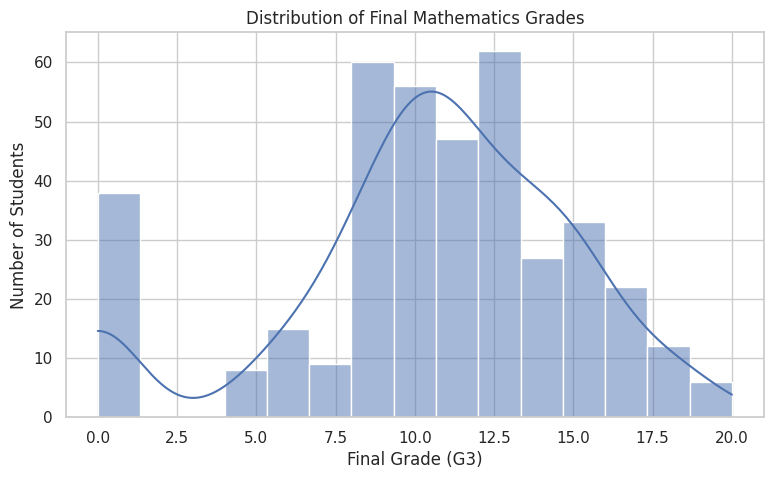

In [5]:

# Summary of final grades

print(df["G3"].describe())

# Distribution of final grades
plt.figure(figsize=(9,5))

sns.histplot(df["G3"], bins=15, kde=True)

plt.title("Distribution of Final Mathematics Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.show()


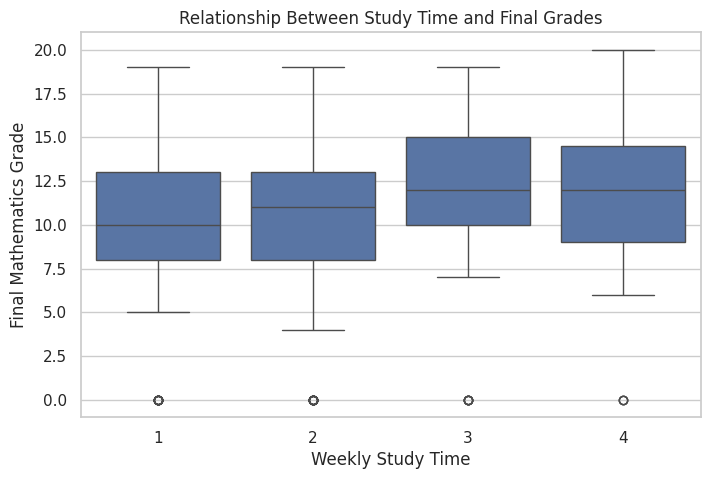

In [6]:

plt.figure(figsize=(8,5))

sns.boxplot(x="studytime", y="G3", data=df)

plt.title("Relationship Between Study Time and Final Grades")
plt.xlabel("Weekly Study Time")
plt.ylabel("Final Mathematics Grade")

plt.show()


In [7]:

study_analysis = df.groupby("studytime")["G3"].agg(
    ["mean", "median", "count"]
)

print(study_analysis)


                mean  median  count
studytime                          
1          10.047619    10.0    105
2          10.171717    11.0    198
3          11.400000    12.0     65
4          11.259259    12.0     27


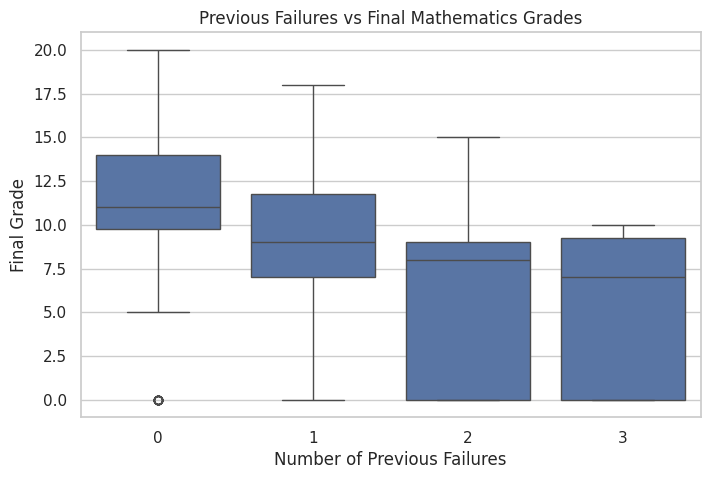

failures
0    11.253205
1     8.120000
2     6.235294
3     5.687500
Name: G3, dtype: float64


In [8]:

plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="failures", y="G3")

plt.title("Previous Failures vs Final Mathematics Grades")
plt.xlabel("Number of Previous Failures")
plt.ylabel("Final Grade")

plt.show()

print(df.groupby("failures")["G3"].mean())


In [15]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


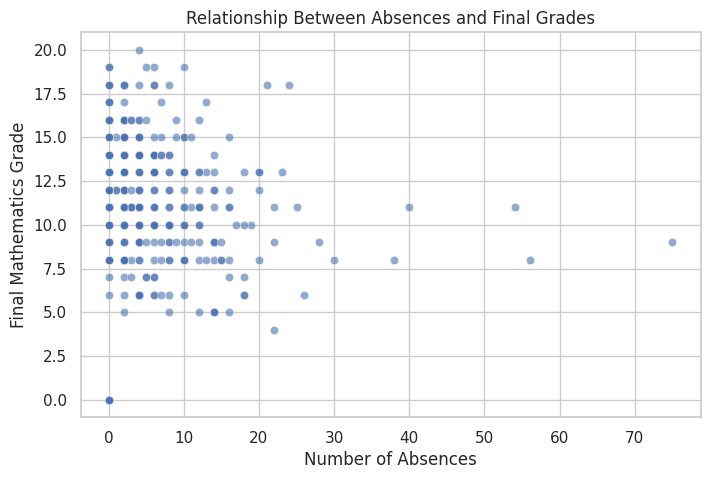

Correlation: 0.03424731615006931


In [9]:

plt.figure(figsize=(8,5))

sns.scatterplot(data=df, x="absences", y="G3", alpha=0.6)

plt.title("Relationship Between Absences and Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Mathematics Grade")

plt.show()

print("Correlation:", df["absences"].corr(df["G3"]))


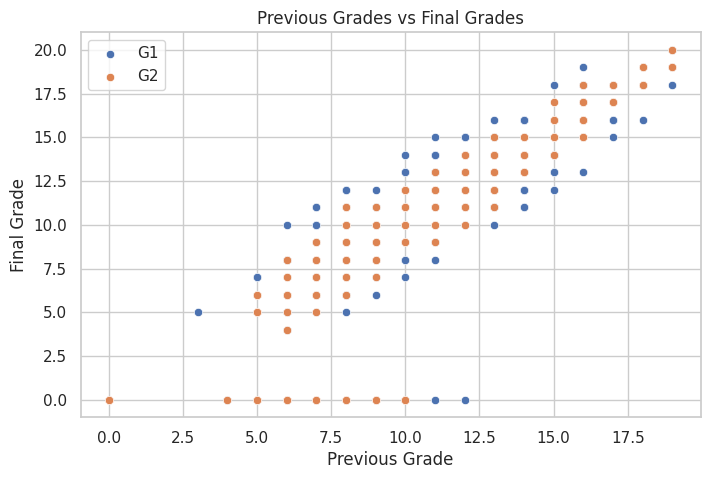

          G1        G2        G3
G1  1.000000  0.852118  0.801468
G2  0.852118  1.000000  0.904868
G3  0.801468  0.904868  1.000000


In [10]:

plt.figure(figsize=(8,5))

sns.scatterplot(data=df, x="G1", y="G3", label="G1")
sns.scatterplot(data=df, x="G2", y="G3", label="G2")

plt.title("Previous Grades vs Final Grades")
plt.xlabel("Previous Grade")
plt.ylabel("Final Grade")

plt.legend()
plt.show()

print(df[["G1", "G2", "G3"]].corr())


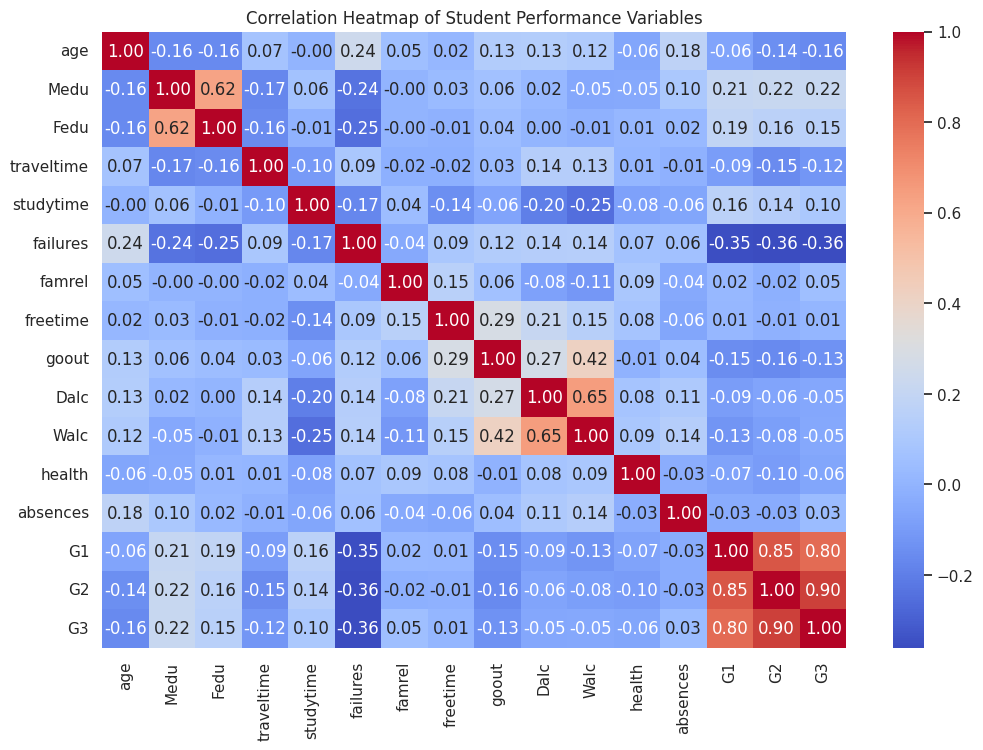

In [11]:

plt.figure(figsize=(12,8))

correlation = df.select_dtypes(include="number").corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Student Performance Variables")
plt.show()


In [12]:

# Separate features and target

X = df.drop("G3", axis=1)
y = df["G3"]

# Identify numerical and categorical columns

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Prepare preprocessing

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Split data

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 316
Testing records: 79


In [13]:

linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression Results")
print("MAE:", mean_absolute_error(y_test, linear_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, linear_predictions)))
print("R2 Score:", r2_score(y_test, linear_predictions))


Linear Regression Results
MAE: 1.64666561971475
RMSE: 2.3783697847961367
R2 Score: 0.7241341236974022


In [14]:

forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

forest_model.fit(X_train, y_train)

forest_predictions = forest_model.predict(X_test)

print("Random Forest Results")
print("MAE:", mean_absolute_error(y_test, forest_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, forest_predictions)))
print("R2 Score:", r2_score(y_test, forest_predictions))


Random Forest Results
MAE: 1.2005063291139242
RMSE: 2.0149658413412745
R2 Score: 0.8019957092176414


In [16]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    forest_model,
    X,
    y,
    cv=5,
    scoring="r2"
)

print("Cross-validation R2 scores:", scores)
print("Mean R2:", scores.mean())
print("Standard deviation:", scores.std())

Cross-validation R2 scores: [0.79464421 0.81831077 0.86540973 0.86943599 0.81953814]
Mean R2: 0.8334677679064046
Standard deviation: 0.029137742071963582
